In [190]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


In [191]:
# Because I like hitchhiker's guide to the galaxy
seed = 42
np.random.seed(seed)

creative_column_names = ['Feature_1', 'Feature_2']

In [192]:
def visualize_dataset(X, y):
    plt.figure(figsize=(8, 6))

    colors = ['#FF0000', '#0000FF']
    class_labels = ['Class 0', 'Class 1']

    for class_val in [0, 1]:
        mask = (y == class_val)
        plt.scatter(
            X[mask, 0],
            X[mask, 1],
            c=colors[class_val],
            label=class_labels[class_val],
            edgecolors='k',
            s=50,
            alpha=0.85
        )



    plt.grid(True, linestyle=':', alpha=0.5)

    plt.legend()
    plt.tight_layout()
    plt.show()

# B1.1 Dataset 1 creation

I used `make_blobs` function to generate two "isotropic Gaussian blobs"

   Feature_1  Feature_2  Class
0   1.560230   3.963242      1
1   1.597078   2.468645      1
2  -2.044383  -1.389077      0
3  -2.101707   0.352278      0
4   2.086857   3.690456      1


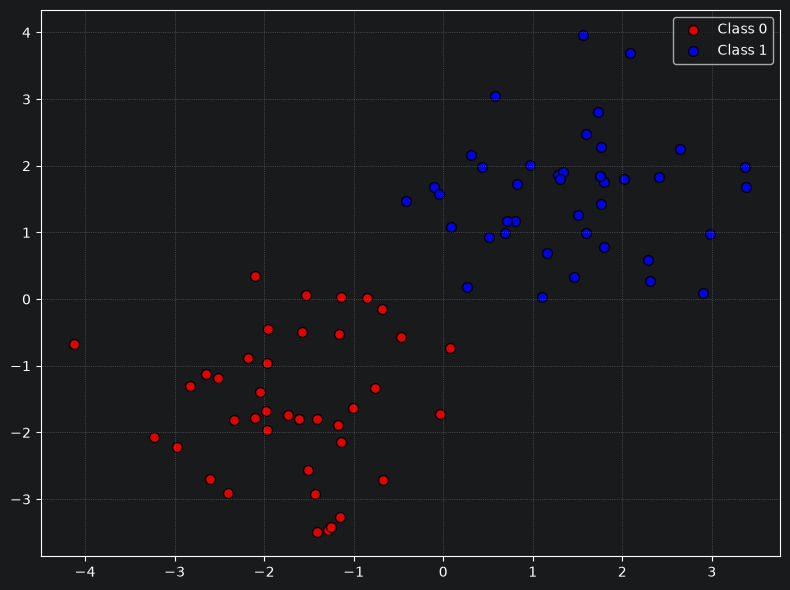

In [193]:
X1, y1 = make_blobs(
    n_samples=80,
    centers=[[-1.5, -1.5], [1.5, 1.5]],
    cluster_std=1.0,
    random_state=seed
)

df1 = pd.DataFrame(X1, columns=creative_column_names)
df1['Class'] = y1
print(df1.head())

visualize_dataset(X1, y1)

# B1.2 Dataset 2 creation (Dataset 1 + outliers)

Outliners are generated using a normal distribution centered at [3.5, 3.5] and [-3.5, -3.5]. This places them inside opposing class’s domain (which centers around [-1.5, -1.5] and [1.5, 1.5]


   Feature_1  Feature_2  Class
0   1.560230   3.963242      1
1   1.597078   2.468645      1
2  -2.044383  -1.389077      0
3  -2.101707   0.352278      0
4   2.086857   3.690456      1


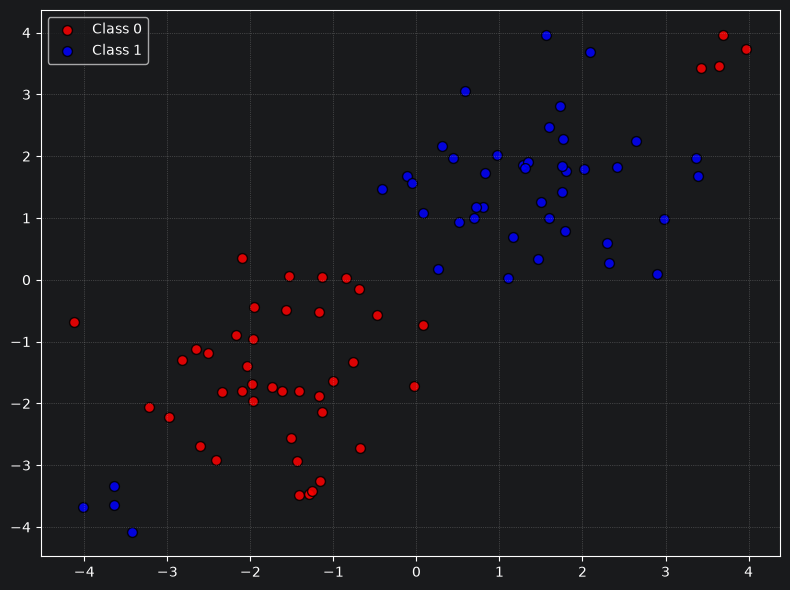

In [194]:
outliers_class0 = np.random.normal(loc=[3.5, 3.5], scale=0.3, size=(4, 2))
y_outliers0 = np.full(4, dtype=int, fill_value=0)

outliers_class1 = np.random.normal(loc=[-3.5, -3.5], scale=0.3, size=(4, 2))
y_outliers1 = np.full(4, dtype=int, fill_value=1)

X2 = np.concatenate([X1, outliers_class0, outliers_class1], axis=0)
y2 = np.concatenate([y1, y_outliers0, y_outliers1], axis=0)

df2 = pd.DataFrame(X2, columns=creative_column_names)
df2['Class'] = y2

# the head is the same, I just got used to print it in the end of the cell
print(df2.head())

visualize_dataset(X2, y2)

# B1.3  Split Dataset 1 and Dataset 2 in training and testing data.

I decided to split datasets into 75% training and 25% testing (normally you would do 80% and 20% respectively, but we have very small datasets 80 and 88 elements and they both are divisible by 4, but not by 5)


In [195]:

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.25, random_state=seed, stratify=y1
)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.25, random_state=seed, stratify=y2
)

B1.4 Train on Dataset 1 and Dataset 2

In [202]:
models = {
    'k-NN': KNeighborsClassifier(n_neighbors=3),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(C=1.0, random_state=seed),
}


def evaluate_dataset(X_tr, X_te, y_tr, y_te):
    for model_name, model in models.items():
        model.fit(X_tr, y_tr)
        train = accuracy_score(y_tr, model.predict(X_tr))
        test = accuracy_score(y_te, model.predict(X_te))
        matrix = confusion_matrix(y_te, model.predict(X_te))

        print(model_name)
        print(f"Train: {train:.4f}")
        print(f"Test: {test:.4f}")
        print(matrix)
        print()

In [203]:
evaluate_dataset(X1_train, X1_test, y1_train, y1_test)

k-NN
Train: 1.0000
Test: 1.0000
[[10  0]
 [ 0 10]]

Naive Bayes
Train: 1.0000
Test: 1.0000
[[10  0]
 [ 0 10]]

Support Vector Machine
Train: 1.0000
Test: 1.0000
[[10  0]
 [ 0 10]]



All three models achieved 100% classification accuracy across both training and test sets. Because the two initial clusters are clean, compact, and widely separated in feature space, a linear or non-linear decision boundary easily isolates the two classes without any misclassifications.

In [204]:
evaluate_dataset(X2_train, X2_test, y2_train, y2_test)

k-NN
Train: 1.0000
Test: 1.0000
[[11  0]
 [ 0 11]]

Naive Bayes
Train: 0.9091
Test: 0.9091
[[10  1]
 [ 1 10]]

Support Vector Machine
Train: 1.0000
Test: 1.0000
[[11  0]
 [ 0 11]]



Naive Bayes 90.91% Accuracy
It looks at the overall average and spread of the entire dataset.
The outliers distort these statistics, shifting the decision line and causing errors.

k-NN 100% Accuracy
It only cares about local neighbors. The outliers create tiny, isolated "islands," but the test points are far enough away to be unaffected.

Support Vector Machine 100% Accuracy
Its flexible boundaries safely wrap around the outliers as tiny exceptions without breaking the main separation line.

B1.5 Explore different values for the regularization parameter and different kernels for the Support Vector Machine classifier

In [205]:
C_values = [0.01, 1.0, 100.0]
kernels = ['linear', 'rbf', 'poly']

for kernel in kernels:
    for c in C_values:
        clf = SVC(kernel=kernel, C=c, random_state=seed)
        clf.fit(X2_train, y2_train)
        test = accuracy_score(y2_test, clf.predict(X2_test))
        print(kernel)
        print(c)
        print(test)
        print()

linear
0.01
0.9090909090909091

linear
1.0
0.9090909090909091

linear
100.0
0.9090909090909091

rbf
0.01
0.9090909090909091

rbf
1.0
1.0

rbf
100.0
1.0

poly
0.01
0.5909090909090909

poly
1.0
0.8181818181818182

poly
100.0
0.9090909090909091



The kernel and the regularization parameter significantly affect the classification accuracy on Dataset 2, as they change how aggressively the model reacts to the injected outliers.

The linear kernel yields an identical accuracy of 90.91\% across all values of C.

The RBF kernel achieves perfect 100\% accuracy at C = 1.0 and C = 100.0, but drops to 90.91\% at C = 0.01.

The polynomial kernel shows a steep performance scaling as C increases, rising from 59.09\% at C = 0.01 up to 90.91\% at C = 100.0.

B1.6 Visualization


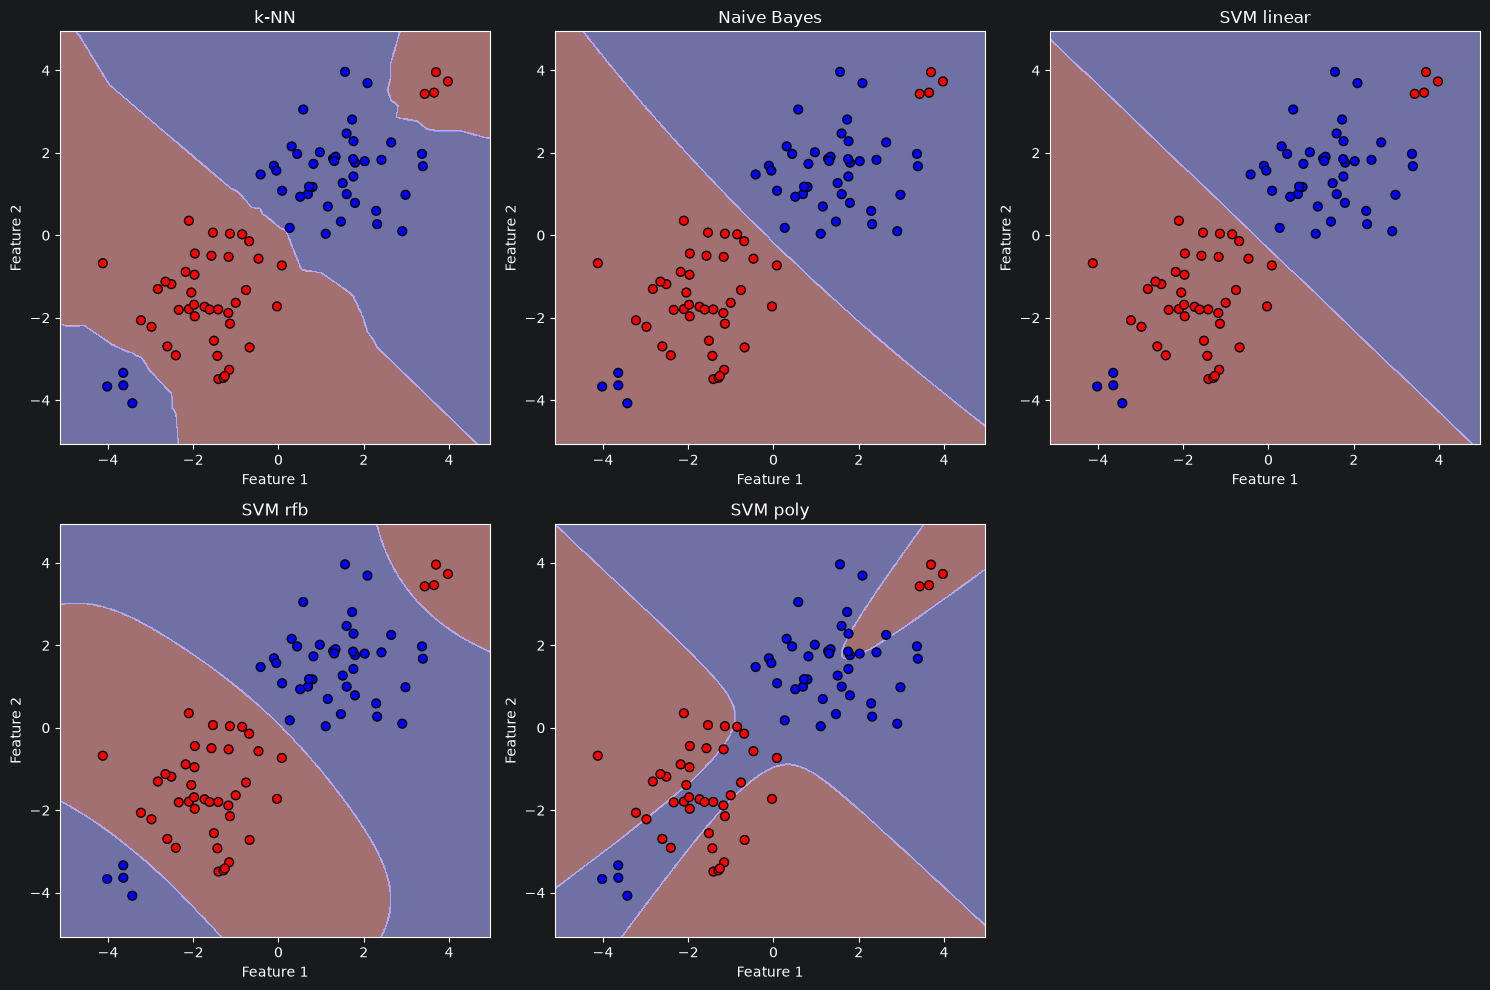

In [208]:
def plot_decision_boundaries(X, y):
    h = 0.02
    cm_bright = ListedColormap(['#FF0000', '#0000FF'])
    cm_back = ListedColormap(['#FFAAAA', '#AAAAFF'])

    plot_models = {
        'k-NN': KNeighborsClassifier(n_neighbors=3),
        'Naive Bayes': GaussianNB(),
        'SVM linear': SVC(kernel='linear', C=1.0),
        'SVM rfb': SVC(kernel='rbf', C=1.0),
        'SVM poly': SVC(kernel='poly', degree=3, C=1.0)
    }

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for ax, (name, clf) in zip(axes, plot_models.items()):
        clf.fit(X, y)
        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        ax.contourf(xx, yy, Z, cmap=cm_back, alpha=0.6)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright, edgecolors='k', s=40)
        ax.set_title(name)
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")

    fig.delaxes(axes[5])
    plt.tight_layout()
    plt.show()


plot_decision_boundaries(X2, y2)

B2

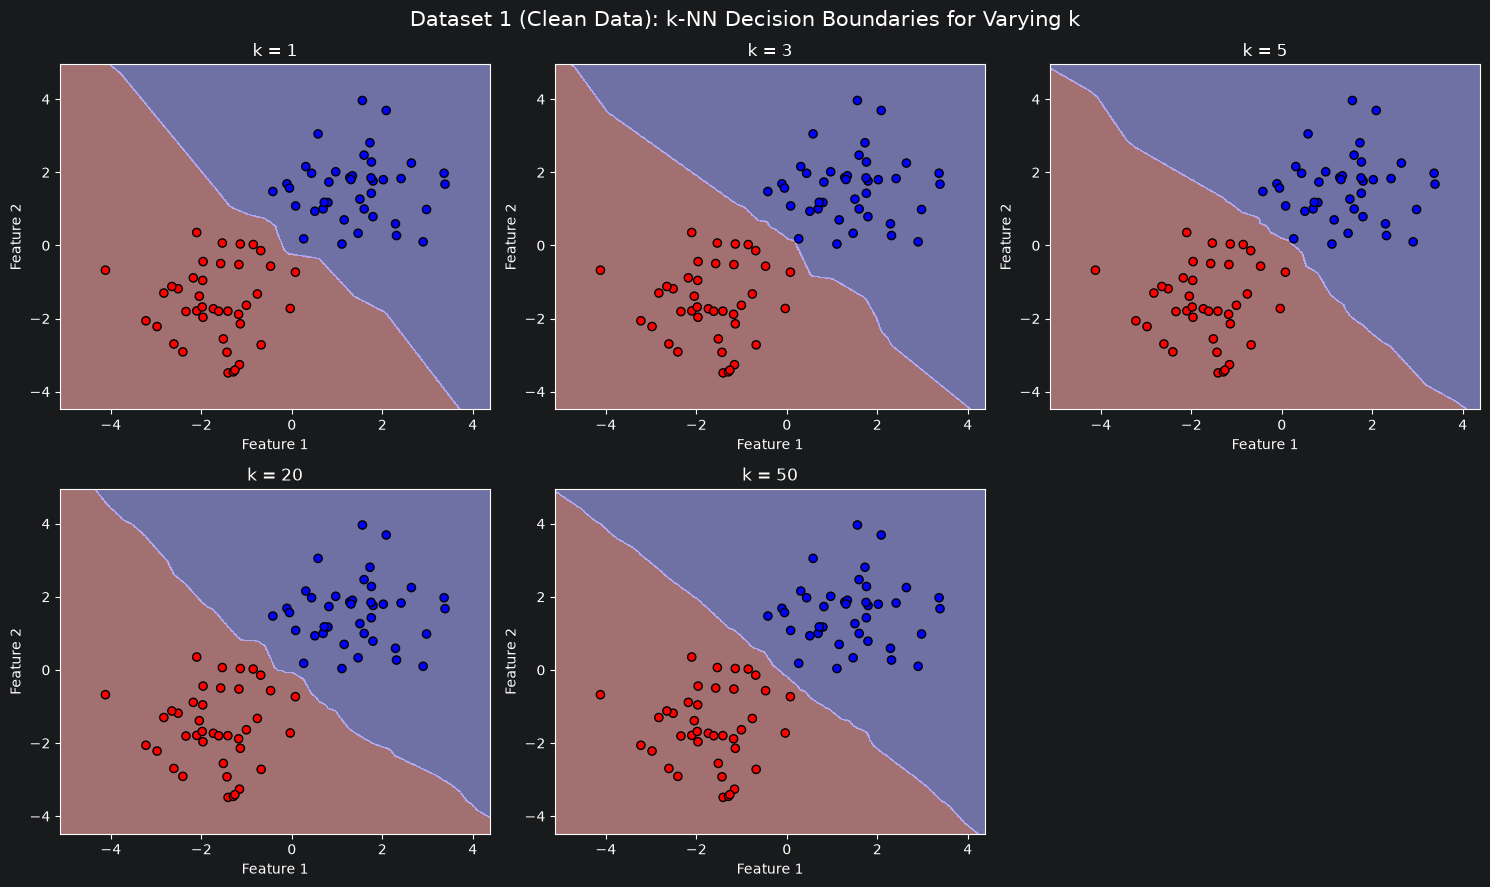

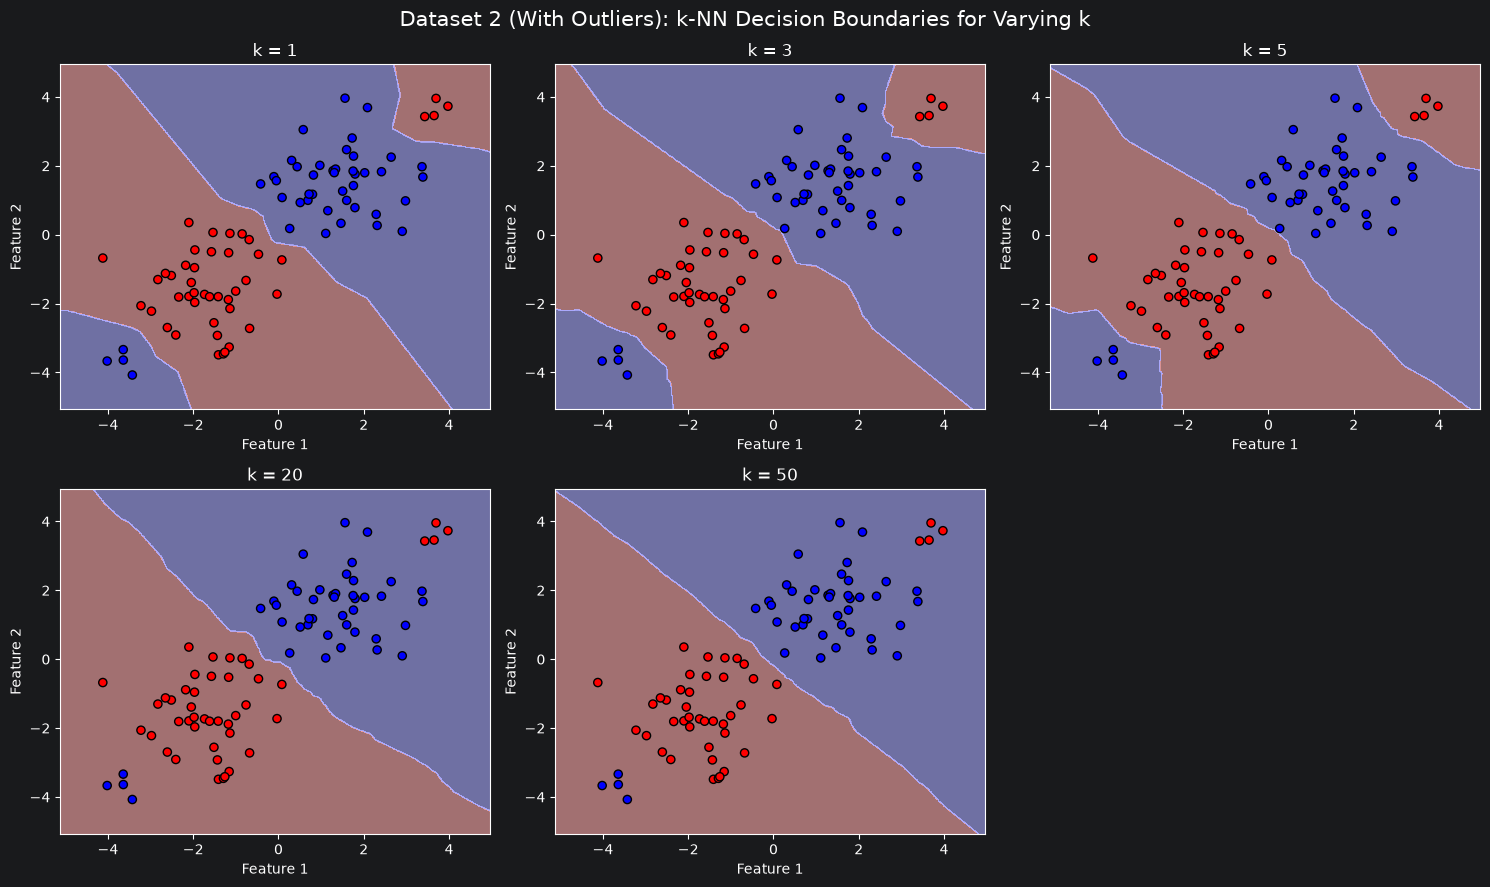

In [201]:
def plot_knn_boundaries(X, y, title_prefix="Dataset"):
    k_values = [1, 3, 5, 20, 50]
    h = 0.02

    cm_bright = ListedColormap(['#FF0000', '#0000FF'])
    cm_back = ListedColormap(['#FFAAAA', '#AAAAFF'])

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()

    for idx, k in enumerate(k_values):
        ax = axes[idx]
        clf = KNeighborsClassifier(n_neighbors=k)
        clf.fit(X, y)

        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        ax.contourf(xx, yy, Z, cmap=cm_back, alpha=0.6)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright, edgecolors='k', s=35)
        ax.set_title(f"k = {k}")
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")

    fig.delaxes(axes[5])
    plt.suptitle(f"{title_prefix}: k-NN Decision Boundaries for Varying k", fontsize=15)
    plt.tight_layout()
    plt.show()


plot_knn_boundaries(X1, y1, title_prefix="Dataset 1 (Clean Data)")
plot_knn_boundaries(X2, y2, title_prefix="Dataset 2 (With Outliers)")